1 . Model Markov ascuns

In [4]:
!pip install hmmlearn -q

import numpy as np
from hmmlearn import hmm

model = hmm.CategoricalHMM(n_components=4, n_features=3, random_state=42,
                           init_params="", params="")

model.startprob_ = np.array([0.25, 0.25, 0.25, 0.25])

model.transmat_ = np.array([
    [0.0, 0.5, 0.0, 0.5],  # din Camera 1 -> spre 2 și 4
    [0.5, 0.0, 0.5, 0.0],  # din Camera 2 -> spre 1 și 3
    [0.0, 0.5, 0.0, 0.5],  # din Camera 3 -> spre 2 și 4
    [0.5, 0.0, 0.5, 0.0],  # din Camera 4 -> spre 1 și 3
])

# Matricea de emisie B (4x3): probabilitățile [R, G, B] pentru fiecare cameră
model.emissionprob_ = np.array([
    [0.7, 0.2, 0.1],  # Camera 1
    [0.2, 0.6, 0.2],  # Camera 2
    [0.1, 0.3, 0.6],  # Camera 3
    [0.5, 0.2, 0.3],  # Camera 4
])

# Secvența de observații: Rosu (0), Verde (1), Albastru (2)
obs = np.array([[0], [1], [2], [2], [0]])

# 1. P(R, G, B) - algoritmul forward
p_obs = np.exp(model.score(obs))

# 2. Cea mai probabila secventa de stari - algoritmul Viterbi
log_p_viterbi, states = model.decode(obs, algorithm="viterbi")
p_viterbi = np.exp(log_p_viterbi)

camere = [f"Camera {s + 1}" for s in states]
print("P(R, G, B) =", round(p_obs, 6))
print("Stari Viterbi =", states + 1)
print("Cea mai probabila secventa de camere:", " -> ".join(camere))
print("P(R, G, B, S*) =", round(p_viterbi, 6))

# Verificare manuală a traseului Viterbi
p_manual = 0.25*0.7 * 0.5*0.6 * 0.5*0.6   # 1 -> 2 -> 3
print("Verificare manuala 1->2->3:", p_manual)

P(R, G, B) = 0.00414
Stari Viterbi = [1 2 3 4 1]
Cea mai probabila secventa de camere: Camera 1 -> Camera 2 -> Camera 3 -> Camera 4 -> Camera 1
P(R, G, B, S*) = 0.000827
Verificare manuala 1->2->3: 0.01575


3. Inferenta Bayesiana

A priori: Beta(2, 8)
  media = 0.2000 | modul = 0.1250 | dispersia = 0.014545 | std = 0.1206
  interval credibil 95% = [0.0281, 0.4825]

A posteriori dupa lotul 1: Beta(7, 28)
  media = 0.2000 | modul = 0.1818 | dispersia = 0.004444 | std = 0.0667
  interval credibil 95% = [0.0870, 0.3453]

A posteriori dupa ambele loturi: Beta(10, 40)
  media = 0.2000 | modul = 0.1875 | dispersia = 0.003137 | std = 0.0560
  interval credibil 95% = [0.1024, 0.3202]

A posteriori doar cu lotul 2: Beta(5, 20)
  media = 0.2000 | modul = 0.1739 | dispersia = 0.006154 | std = 0.0784
  interval credibil 95% = [0.0713, 0.3738]

EMV lot 1 = x/n = 0.2
Verificare: toate datele odata -> Beta(10, 40)
P(theta > 0.3 | ambele loturi) = 0.0480


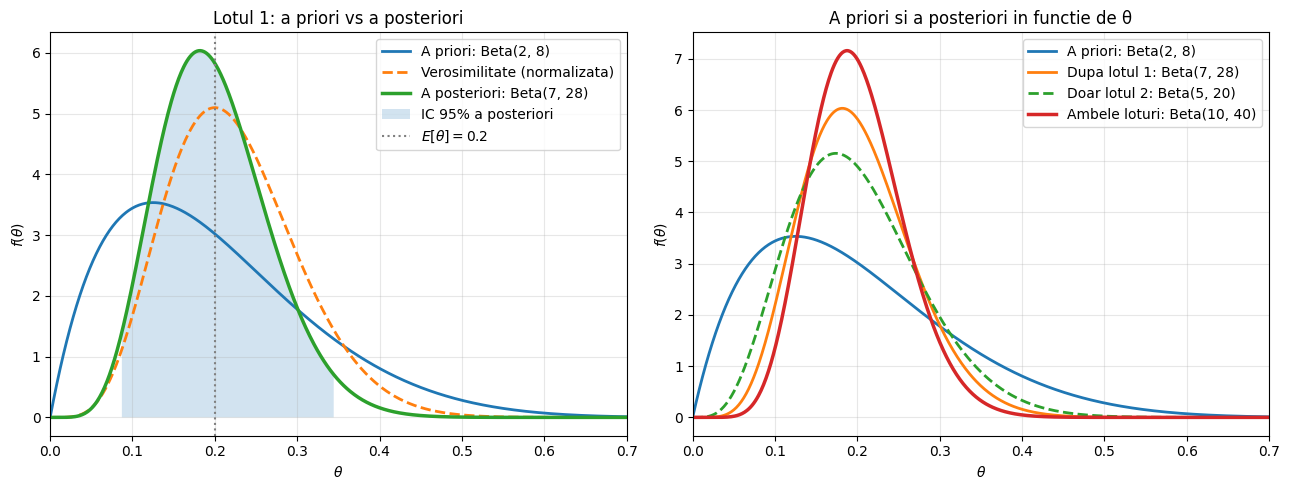

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

def rezumat(a, b, nume):
    media = a / (a + b)
    modul = (a - 1) / (a + b - 2)
    var = a * b / ((a + b)**2 * (a + b + 1))
    ic = stats.beta(a, b).ppf([0.025, 0.975])
    print(f"{nume}: Beta({a}, {b})")
    print(f"  media = {media:.4f} | modul = {modul:.4f} | "
          f"dispersia = {var:.6f} | std = {np.sqrt(var):.4f}")
    print(f"  interval credibil 95% = [{ic[0]:.4f}, {ic[1]:.4f}]\n")

# Prior
a0, b0 = 2, 8

# Lot 1
n1, x1 = 25, 5
a1, b1 = a0 + x1, b0 + (n1 - x1)          # Beta(7, 28)

# Lot 2
n2, x2 = 15, 3
a12, b12 = a1 + x2, b1 + (n2 - x2)        # ambele loturi: Beta(10, 40)
a2, b2 = a0 + x2, b0 + (n2 - x2)          # doar lotul 2:  Beta(5, 20)

#Rezultate
rezumat(a0, b0, "A priori")
rezumat(a1, b1, "A posteriori dupa lotul 1")
rezumat(a12, b12, "A posteriori dupa ambele loturi")
rezumat(a2, b2, "A posteriori doar cu lotul 2")

print("EMV lot 1 = x/n =", x1 / n1)
print("Verificare: toate datele odata ->",
      f"Beta({a0 + x1 + x2}, {b0 + (n1 + n2) - (x1 + x2)})")
print(f"P(theta > 0.3 | ambele loturi) = {stats.beta(a12, b12).sf(0.3):.4f}")

#Grafice: densitatile in functie de theta
theta = np.linspace(0, 1, 1000)
prior   = stats.beta(a0, b0).pdf(theta)
post_1  = stats.beta(a1, b1).pdf(theta)
post_2  = stats.beta(a2, b2).pdf(theta)
post_12 = stats.beta(a12, b12).pdf(theta)
lik_1   = stats.beta(x1 + 1, n1 - x1 + 1).pdf(theta)   # verosimilitate normalizata

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

#Lotul 1: prior
ax[0].plot(theta, prior,  lw=2, label=f"A priori: Beta({a0}, {b0})")
ax[0].plot(theta, lik_1,  lw=2, ls="--", label="Verosimilitate (normalizata)")
ax[0].plot(theta, post_1, lw=2.5, label=f"A posteriori: Beta({a1}, {b1})")
lo, hi = stats.beta(a1, b1).ppf([0.025, 0.975])
ax[0].fill_between(theta, post_1, where=(theta >= lo) & (theta <= hi),
                   alpha=0.2, label="IC 95% a posteriori")
ax[0].axvline(0.2, color="gray", ls=":", label=r"$E[\theta]=0.2$")
ax[0].set_title("Lotul 1: a priori vs a posteriori")
ax[0].set_xlabel(r"$\theta$"); ax[0].set_ylabel(r"$f(\theta)$")
ax[0].set_xlim(0, 0.7); ax[0].legend(); ax[0].grid(alpha=0.3)

#Toate distributiile
ax[1].plot(theta, prior,   lw=2, label=f"A priori: Beta({a0}, {b0})")
ax[1].plot(theta, post_1,  lw=2, label=f"Dupa lotul 1: Beta({a1}, {b1})")
ax[1].plot(theta, post_2,  lw=2, ls="--", label=f"Doar lotul 2: Beta({a2}, {b2})")
ax[1].plot(theta, post_12, lw=2.5, label=f"Ambele loturi: Beta({a12}, {b12})")
ax[1].set_title("A priori si a posteriori in functie de θ")
ax[1].set_xlabel(r"$\theta$"); ax[1].set_ylabel(r"$f(\theta)$")
ax[1].set_xlim(0, 0.7); ax[1].legend(); ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Diferente intre b si c :
Ambele loturi: Beta(10, 40). Pornești de la Beta(2, 8) și adaugi tot ce am observat: 8 defecte din 40 de produse. Posteriorul de după primul lot, Beta(7, 28), devine a priori pentru al doilea lot.

Doar al doilea lot: Beta(5, 20). Pornesc tot de la Beta(2, 8), dar folosim numai cele 15 produse, cu 3 defecte. E ca si cum lotul 1 n-ar fi existat.

Ambele loturi au aceeași proporție de defecte ca a priori-ul: 5/25 = 3/15 = 0,Datele nu muta estimarea, ci doar o confirma . Dacă al doilea lot ar fi avut, de exemplu, 9 defecte din 15, mediile ar fi iesit diferite.

Ce se schimbă e precizia. Suma alfa + beta arata cata informatie ai acumulat. O vedem ca obiecte vazute cele 10 „virtuale” din a priori plus cele observate.


2 Retele Markov

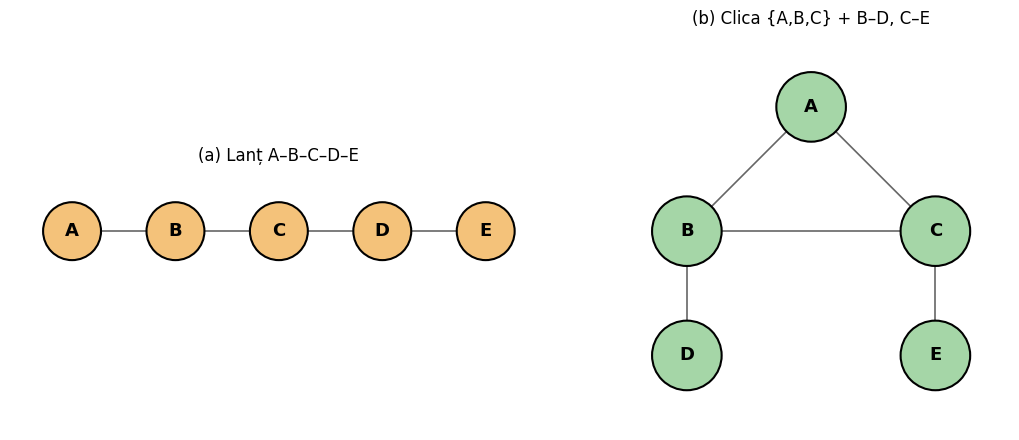

     P(A | B=1, C=0)
     vecinatatea Markov a lui A = {B}
     => P(A | B, C) = f_AB(A, B) / Σ_A f_AB(A, B)
     forta bruta : [0.516358 0.483642]
     formula     : [0.516358 0.483642]
     coincid?    : True
     P(D | A=0, B=1, C=1, E=0)
     vecinatatea Markov a lui D = {B}
     => P(D | A,B,C,E) = g_BD(B, D) / Σ_D g_BD(B, D)
     forta bruta : [0.424134 0.575866]
     formula     : [0.424134 0.575866]
     coincid?    : True


In [6]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle


#vizualizarea grafurilor

def plot_graf(axa, coord, legaturi, eticheta, fill):
    for n1, n2 in legaturi:
        (x1, y1), (x2, y2) = coord[n1], coord[n2]
        axa.plot([x1, x2], [y1, y2], "k-", lw=1.2, alpha=0.6)
    for nod, (x, y) in coord.items():
        axa.add_patch(Circle((x, y), 0.28, facecolor=fill,
                             edgecolor="k", lw=1.5, zorder=5))
        axa.annotate(nod, (x, y), ha="center", va="center",
                     fontsize=13, weight="bold", zorder=6)
    xs = [p[0] for p in coord.values()]
    ys = [p[1] for p in coord.values()]
    axa.set_xlim(min(xs) - 0.6, max(xs) + 0.6)
    axa.set_ylim(min(ys) - 0.6, max(ys) + 0.6)
    axa.set_aspect("equal")
    axa.set_axis_off()
    axa.set_title(eticheta, fontsize=12)


graf_a = {
    "coord": {lit: (i, 0) for i, lit in enumerate("ABCDE")},
    "legaturi": list(zip("ABCD", "BCDE")),
}
graf_b = {
    "coord": {"A": (1, 2), "B": (0, 1), "C": (2, 1), "D": (0, 0), "E": (2, 0)},
    "legaturi": [("A", "B"), ("A", "C"), ("B", "C"), ("B", "D"), ("C", "E")],
}

figura, (st, dr) = plt.subplots(ncols=2, figsize=(11, 4.5))
plot_graf(st, graf_a["coord"], graf_a["legaturi"], "(a) Lanț A–B–C–D–E", "#f4c27a")
plot_graf(dr, graf_b["coord"], graf_b["legaturi"], "(b) Clica {A,B,C} + B–D, C–E", "#a5d6a7")
figura.tight_layout()
figura.savefig("grafuri_mrf.png", dpi=120)
plt.show()


#distributia comuna din factori

np.random.seed(7)

def factor_aleator(*dim):
    """Potential pozitiv cu valori in [0.1, 1)."""
    return 0.1 + 0.9 * np.random.rand(*dim)

def distributie_comuna(factori, n_var=5):
    """factori = lista de (indici_variabile, tabel). Construieste P prin produs explicit."""
    tabel = np.zeros((2,) * n_var)
    for config in itertools.product([0, 1], repeat=n_var):
        produs = 1.0
        for idx, f in factori:
            produs *= f[tuple(config[i] for i in idx)]
        tabel[config] = produs
    Z = tabel.sum()
    return tabel / Z

def conditionata(P, tinta, evidenta):
    """P(tinta | evidenta) prin forta bruta: fixeaza evidenta, insumeaza restul."""
    rezultat = np.zeros(2)
    for config in itertools.product([0, 1], repeat=P.ndim):
        if all(config[k] == v for k, v in evidenta.items()):
            rezultat[config[tinta]] += P[config]
    return rezultat / rezultat.sum()

A, B, C, D, E = range(5)


#Lant: P(A | B, C) se reduce la P(A | B) ----
f_AB, f_BC, f_CD, f_DE = (factor_aleator(2, 2) for _ in range(4))
P1 = distributie_comuna([((A, B), f_AB), ((B, C), f_BC),
                         ((C, D), f_CD), ((D, E), f_DE)])

ev_a = {B: 1, C: 0}
brut_a = conditionata(P1, A, ev_a)
coloana = f_AB[:, ev_a[B]]
redus_a = coloana / np.sum(coloana)   # doar vecinul B conteaza

print("=" * 45)
print("     P(A | B=1, C=0)")
print("     vecinatatea Markov a lui A = {B}")
print("     => P(A | B, C) = f_AB(A, B) / Σ_A f_AB(A, B)")
print(f"     forta bruta : {brut_a.round(6)}")
print(f"     formula     : {redus_a.round(6)}")
print(f"     coincid?    : {np.allclose(brut_a, redus_a)}")


#Clica + 2 muchii: P(D | A, B, C, E) se reduce la P(D | B)
g_ABC = factor_aleator(2, 2, 2)
g_BD = factor_aleator(2, 2)
g_CE = factor_aleator(2, 2)
P2 = distributie_comuna([((A, B, C), g_ABC), ((B, D), g_BD), ((C, E), g_CE)])

ev_b = {A: 0, B: 1, C: 1, E: 0}
brut_b = conditionata(P2, D, ev_b)
rand = g_BD[ev_b[B], :]
redus_b = rand / np.sum(rand)         # doar vecinul B

print("=" * 45)
print("     P(D | A=0, B=1, C=1, E=0)")
print("     vecinatatea Markov a lui D = {B}")
print("     => P(D | A,B,C,E) = g_BD(B, D) / Σ_D g_BD(B, D)")
print(f"     forta bruta : {brut_b.round(6)}")
print(f"     formula     : {redus_b.round(6)}")
print(f"     coincid?    : {np.allclose(brut_b, redus_b)}")
print("=" * 45)